# 🚀 Proiect 1 - Predicția plecării clienților (Telco Customer Churn)

## 🗄️ 1. Explorarea datelor

📚 1.a) Se încarcă bibliotecile și setul de date

`pandas` e o bibliotecă pentru organizarea, prelucrarea și analiza datelor în tabel. `matplotlib` e o bibliotecă pentru crearea graficelor și vizualizarea datelor. `seaborn` e bazată pe `matplotlib` și creează grafice mai simplu și mai intuitiv.

Folosesc metoda `df.head()` pentru a vedea cum sunt organizate datele și a verifica dacă au fost încărcate corect.

Coloanele cele mai relevante
| Coloana | Explicație |
|---|---|
| tenure | De câte luni e clientul abonat |
| Contract | Tipul contractului: lunar, 1 an, 2 ani |
| MonthlyCharges | Cât plătește pe lună |
| TotalCharges | Cât a plătit în total până acum |
| Churn | "Yes" (=a plecat), "No" (=a rămas) |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


📏 1.b) Verific dimensiunea și tipurile coloanelor pentru a înțelege cum sunt organizate datele și dacă sunt pregătite pentru analiză.

In [2]:
print(f"Dimensiune (randuri, coloane): {df.shape}")
df.info()

Dimensiune (randuri, coloane): (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBi

**👀 Interpretare:** Setul conține 7.043 de clienți și 21 de coloane (3 coloane numerice și 18 de tip text). `TotalCharges` conține sume, dar este citită ca text. Trebuie să verific valorile și să o convertesc în format numeric pentru a putea analiza corect sumele și a o folosi în modelele de ML.

⭕ 1.c) Convertesc `TotalCharges` în număr pentru a putea analiza sumele. Cu `errors="coerce"`, valorile care nu pot fi convertite devin `NaN`, apoi verific câte valori lipsesc.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isna().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Vreau să verific dacă valorile lipsă din `TotalCharges` au legătură cu vechimea contractului și taxa lunară a clienților.

In [4]:
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


**👀 Interpretare:** Cele 11 valori lipsă apar la clienții cu `tenure = 0`, adică sunt la începutul contractului și nu au plătit încă nicio sumă. Deși `TotalCharges` lipsește, `MonthlyCharges` are o valoare, deci acești clienți au deja o taxă lunară stabilită.

📈 1.d) Mă uit câți clienți pleacă și câți rămân, ca să văd dacă datele sunt dezechilibrate. Acest lucru contează când aleg și evaluez modelul de clasificare.

In [5]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


Grafic 1: Câți pleacă vs câți rămân

Reprezint datele într-un grafic ca să compar mai ușor numărul clienților care pleacă cu cel al clienților care rămân și să observ diferența dintre cele două categorii.

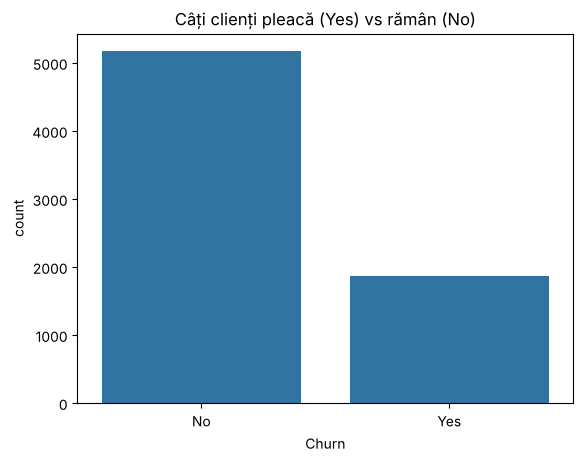

In [6]:
sns.countplot(data=df, x="Churn")
plt.title("Câți clienți pleacă (Yes) vs rămân (No)")
plt.show()

**👀 Interpretare:**
Bara "No" este mai înaltă decât bara "Yes": din totalul de 7043 de clienți, 73.46% au rămas, iar 26.54% au renunțat la servicii. Asta înseamnă că datele sunt dezechilibrate. Un model care ar răspunde mereu "No" ar avea o acuratețe de ~73%, fără să învețe nimic. De aceea ne vom uita mai mult la recall pe clasa "Yes", împreună cu precision și F1.

Grafic 2: Plecările după tipul contractului. Mă uit la tipul contractului pentru a vedea dacă există o legătură între durata acestuia și plecarea clienților.

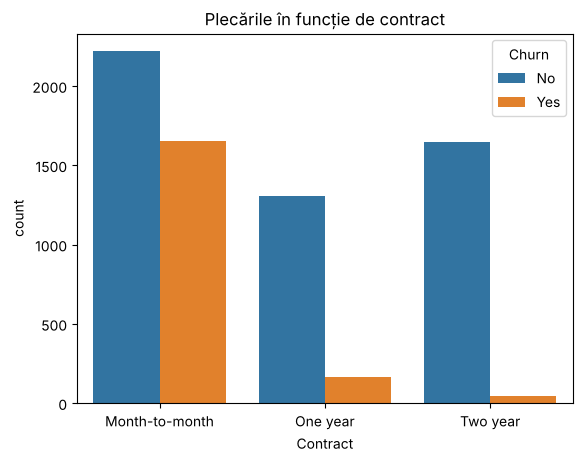

In [7]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Plecările în funcție de contract")
plt.show()

Calculez procentele ca să văd mai ușor ce tip de contract are cea mai mare rată de plecare a clienților.

In [8]:
(pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100).round(1)

Churn,No,Yes
Contract,,
Month-to-month,57.3,42.7
One year,88.7,11.3
Two year,97.2,2.8


**👀 Interpretare:** Clienții cu contract lunar pleacă cel mai des (43%), față de cei cu contract pe un an (11%) și cei cu contract pe doi ani (3%). Probabil, cei cu contract lunar se pot răzgândi mai ușor, pentru că nu sunt legați de un contract pe termen lung.

Grafic 3: Vechimea clientului. Mă uit la vechimea clienților pentru a vedea dacă cei care sunt clienți de mai mult timp pleacă mai rar.

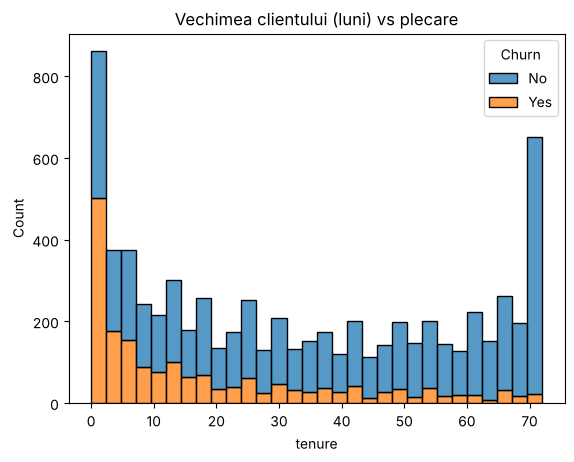

In [9]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Vechimea clientului (luni) vs plecare")
plt.show()

**👀 Interpretare:** Cele mai multe plecări se observă în primele luni ca client. Pe măsură ce vechimea crește, numărul clienților care pleacă scade, mai ales spre 60–72 de luni. Se pare că pleacă mai ales clienții noi, nu cei vechi.

❓ **Întrebarea pasului 1:** E clasificare sau regresie? Ce greșeală a modelului ar costa mai mult în realitate?

Este o problemă de clasificare binară, deoarece vrem să prezicem dacă un client pleacă (`Yes`) sau rămâne (`No`). Cea mai costisitoare greșeală este un fals negativ: modelul prezice că un client rămâne, dar acesta pleacă, iar firma pierde ocazia de a-l păstra. Un fals pozitiv poate duce la oferirea inutilă a unei reduceri unui client care ar fi rămas oricum. De aceea, este important să identificăm cât mai mulți clienți care pleacă, urmărind metrica recall pentru clasa `Yes`.

---
## 🧹 2. Pregătirea datelor

Completez cele 11 valori lipsă cu 0 deoarece acești clienți au `tenure = 0`, deci sunt la începutul relației cu firma și nu au acumulat încă taxe totale. Astfel, păstrez în analiză acești clienți fără să inventez o valoare pozitivă pentru `TotalCharges`.

In [10]:
# Cei 11 clienți cu TotalCharges lipsă au tenure = 0, deci nu au plătit încă nimic -> 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Valori lipsă rămase:", df["TotalCharges"].isna().sum())

Valori lipsă rămase: 0


Elimin `customerID` deoarece este un identificator unic, fără semnificație predictivă utilă pentru model. Transform `Churn` în 0/1 pentru ca algoritmii să poată învăța și prezice numeric dacă un client pleacă (`1`) sau rămâne (`0`).

In [11]:
# customerID e doar un cod unic, nu ajută la predicție
df_model = df.drop(columns=["customerID"])

# Coloana de prezis: Yes -> 1 (pleacă), No -> 0 (rămâne)
y = (df_model["Churn"] == "Yes").astype(int)
X = df_model.drop(columns=["Churn"])

print("X:", X.shape, "| y:", y.shape)

X: (7043, 19) | y: (7043,)


Algoritmii folosiți au nevoie de valori numerice, nu de categorii text. `pd.get_dummies` transformă fiecare categorie într-o coloană indicator cu valori 0/1, astfel încât informația să poată fi folosită de model.

In [12]:
# One-hot encoding: fiecare categorie devine o coloană 0/1
# drop_first=True scoate o coloană din fiecare grup (e redundantă)
X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Număr de coloane după transformare:", X.shape[1])
X.head()

Număr de coloane după transformare: 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


Împart datele pentru a antrena modelul pe `train` și a evalua performanța pe date nevăzute, din `test`. `test_size=0.2` rezervă 20% pentru test, iar `stratify=y` păstrează aproximativ aceeași proporție de clienți care pleacă în ambele seturi.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Procent plecări în train:", round(y_train.mean() * 100, 1), "%")
print("Procent plecări în test: ", round(y_test.mean() * 100, 1), "%")

Train: (5634, 30) | Test: (1409, 30)
Procent plecări în train: 26.5 %
Procent plecări în test:  26.5 %


Scalez coloanele numerice pentru a le aduce la scări comparabile, lucru util mai ales pentru regresia logistică. Fac `fit` doar pe `train` ca să nu folosesc informații din setul de test și să evit scurgerea de date (*data leakage*).

In [14]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()
# fit_transform pe train: învață media și deviația DOAR din train
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
# transform pe test: folosește media și deviația din train
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


❓ **Întrebarea pasului 2:** De ce împărțim datele înainte de scalare?

**Răspuns:** Împărțim datele înainte de scalare ca să calculăm media și deviația standard doar din setul de antrenare. Dacă am scala înainte, informații din setul de test ar influența pregătirea datelor și evaluarea ar fi mai puțin corectă.

---
## 🎲 3. Baseline

`DummyClassifier(strategy="most_frequent")` prezice mereu clasa cea mai frecventă, aici `No`. Este un baseline simplu, cu care compar modelele reale ca să verific dacă acestea învață să identifice plecările mai bine decât o regulă naivă.

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred_dummy), 3))
print("Precision:", round(precision_score(y_test, y_pred_dummy, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, y_pred_dummy), 3))
print("F1       :", round(f1_score(y_test, y_pred_dummy), 3))

Accuracy : 0.735
Precision: 0.0
Recall   : 0.0


F1       : 0.0


❓ **Întrebarea pasului 3:** Ce scor are un model care nu știe nimic?

**Răspuns:** Baseline-ul are accuracy de 0,735, dar recall și F1 pentru clasa `Yes` sunt 0, deoarece prezice că toți clienții rămân și nu identifică nicio plecare. De aceea, accuracy singur poate induce în eroare când clasele sunt dezechilibrate.

---
## 🤖 4. Antrenarea modelelor

`class_weight="balanced"` acordă o pondere mai mare clasei mai rare în timpul antrenării. Îl folosesc deoarece doar aproximativ 26,5% dintre clienți pleacă, iar identificarea acestei clase este importantă pentru problemă.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# class_weight="balanced": greșelile pe clasa rară (Yes) contează mai mult
models = {
    "Regresie logistică": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Arbore de decizie": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"{name}: antrenat")

Regresie logistică: antrenat
Arbore de decizie: antrenat


Random Forest: antrenat


🎁 **Bonus – GridSearchCV.** `GridSearchCV` testează combinații de hiperparametri folosind cross-validation și selectează combinația cu cel mai bun scor. Optimizez după F1 pentru a echilibra precision și recall pentru clasa `Yes`, în loc să favorizez doar accuracy.

In [17]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 8, 12],
    "min_samples_leaf": [1, 5],
}
grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid, scoring="f1", cv=5, n_jobs=-1
)
grid.fit(X_train, y_train)

print("Cei mai buni parametri:", grid.best_params_)
print("F1 mediu în cross-validation:", round(grid.best_score_, 3))

models["Random Forest (GridSearch)"] = grid.best_estimator_
predictions["Random Forest (GridSearch)"] = grid.best_estimator_.predict(X_test)

Cei mai buni parametri: {'max_depth': 12, 'min_samples_leaf': 5, 'n_estimators': 200}
F1 mediu în cross-validation: 0.636


---
## 📊 5. Evaluarea pe setul de test

Tabelul compară modelele prin accuracy, precision, recall și F1; Random Forest are cel mai mare F1 afișat (0,633), foarte apropiat de varianta optimizată cu GridSearch (0,632). Compararea cu baseline-ul arată dacă modelele detectează plecările, lucru pe care baseline-ul nu îl face deloc.

In [18]:
rows = [("Baseline (Dummy)", y_pred_dummy)] + list(predictions.items())
results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    }
    for name, pred in rows
]).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1
Model,,,,
Baseline (Dummy),0.735,0.000,0.000,0.000
Regresie logistică,0.738,0.504,0.783,0.614
Arbore de decizie,0.735,0.500,0.807,0.618
Random Forest,0.759,0.532,0.781,0.633
Random Forest (GridSearch),0.758,0.530,0.783,0.632


Matricea de confuzie compară valorile reale cu predicțiile și arată câte cazuri sunt corect sau greșit clasificate. Falsurile negative sunt clienții care au plecat în realitate (`Yes`), dar modelul i-a prezis ca rămași (`No`); apar în celula pentru real `Yes` și prezis `No`.

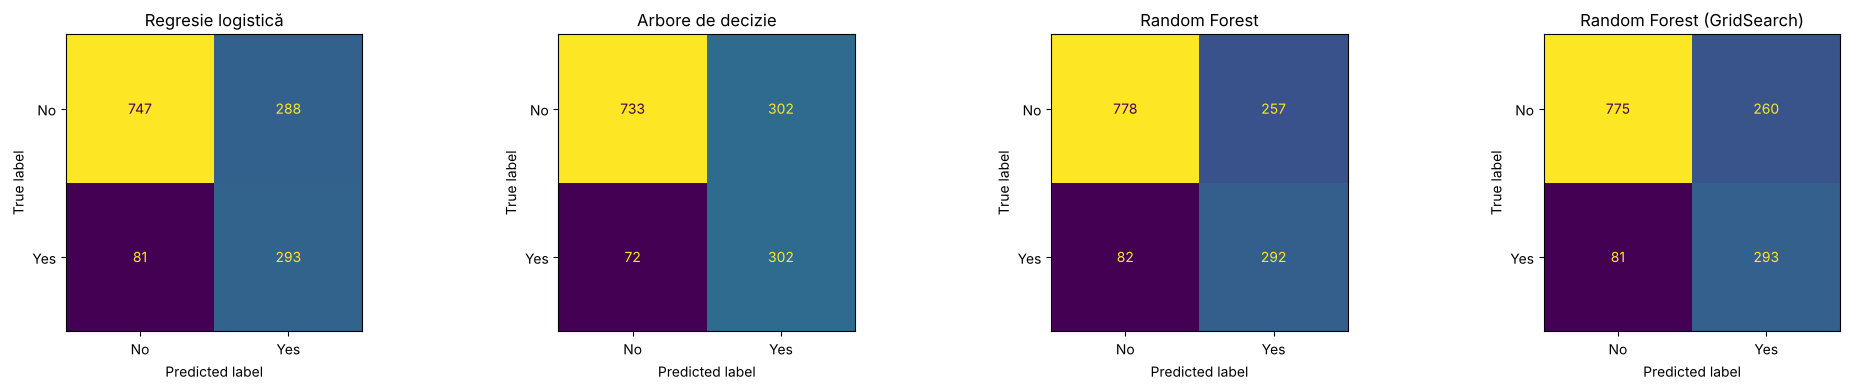

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["No", "Yes"], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

Raportul detaliat arată separat precision, recall și F1 pentru fiecare clasă, nu doar scorul general. Pentru modelul ales, recall-ul clasei `Yes` este 0,78, deci identifică aproximativ 78% dintre clienții care pleacă, deși precision-ul de 0,53 arată că există și alarme false.

In [20]:
from sklearn.metrics import classification_report

# Varianta A: metrica principală e recall-ul pe clasa Yes.
# Păstrez modelele cu recall apropiat de cel mai bun (diferență sub 0,05),
# iar dintre ele îl aleg pe cel cu F1 cel mai mare (mai puține alarme false).
candidates = results.drop(index="Baseline (Dummy)")
close = candidates[candidates["Recall"] >= candidates["Recall"].max() - 0.05]
best_name = close["F1"].idxmax()

print("Modele cu recall apropiat de maxim:", list(close.index))
print("Modelul ales:", best_name)
print(classification_report(y_test, predictions[best_name], target_names=["No", "Yes"]))

Modele cu recall apropiat de maxim: ['Regresie logistică', 'Arbore de decizie', 'Random Forest', 'Random Forest (GridSearch)']
Modelul ales: Random Forest
              precision    recall  f1-score   support

          No       0.90      0.75      0.82      1035
         Yes       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



🎁 **Bonus – importanța coloanelor.** Importanța unei coloane arată cât de mult a contribuit acea caracteristică la deciziile modelului, în cadrul metodei folosite. O pot compara cu observațiile din analiza exploratorie, dar importanța nu dovedește că o coloană cauzează plecarea clientului.

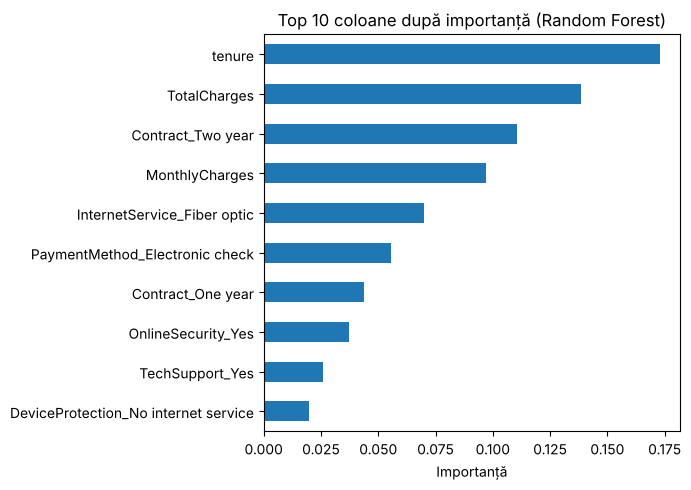

In [21]:
importances = pd.Series(
    models["Random Forest (GridSearch)"].feature_importances_, index=X_train.columns
).sort_values(ascending=False).head(10)

importances.sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Top 10 coloane după importanță (Random Forest)")
plt.xlabel("Importanță")
plt.tight_layout()
plt.show()

❓ **Întrebarea pasului 4:** Care a ieșit mai bine și de ce credeți că s-a întâmplat asta?

**Răspuns:** În rezultatele afișate, Random Forest are cel mai mare F1 (0,633), foarte puțin peste GridSearch (0,632), arborele de decizie (0,618) și regresia logistică (0,614). Diferențele sunt mici, iar varianta optimizată nu a îmbunătățit F1 pe acest test față de Random Forest inițial. Probabil, Random Forest a obținut un rezultat puțin mai bun deoarece combină predicțiile mai multor arbori și poate surprinde relații mai complexe dintre caracteristici, reducând dependența de un singur arbore.

❓ **Întrebarea pasului 5:** De ce ați ales metrica principală pe care ați ales-o?

**Răspuns:** Aleg recall pentru clasa `Yes` ca metrică principală, deoarece un fals negativ înseamnă să nu identificăm un client care urmează să plece. F1 rămâne util pentru comparația modelelor, fiindcă ține cont atât de recall, cât și de precision.

---
## ✅ 6. Concluzie

❓ Ce model recomandați, cât de mult bate baseline-ul și o limitare a analizei.

**Răspuns:** Aș recomanda Random Forest dintre modelele testate, deoarece are cel mai mare F1 afișat (0,633) și recall de 0,78 pentru clienții care pleacă, mult peste baseline-ul cu recall 0. Deși arborele de decizie are un recall puțin mai mare, aleg Random Forest pentru echilibrul mai bun dintre recall și precision, reflectat de F1-ul superior; dacă obiectivul ar fi exclusiv identificarea cât mai multor clienți care pleacă, ar trebui comparat cu atenție și arborele. Totuși, precision-ul de 0,53 implică alarme false, iar analiza ar trebui validată și pe alte date înainte de folosirea în producție.